In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (35064, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [3]:

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_report.sort_values(
    "Missing Percentage",
    ascending=False
))


,Missing Values,Missing Percentage
CO,1776,5.07
O3,1719,4.90
NO2,1023,2.92
SO2,935,2.67
PM2.5,925,2.64
PM10,718,2.05
wd,81,0.23
RAIN,20,0.06
DEWP,20,0.06
PRES,20,0.06


In [4]:

print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

timestamp_cols = ["year", "month", "day", "hour"]

print(
    "Duplicate timestamps:",
    df.duplicated(subset=timestamp_cols).sum()
)


Total rows: 35064
Duplicate rows: 0
Duplicate timestamps: 0


In [5]:

df["timestamp"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]],
    errors="coerce"
)

print("Invalid timestamps:", df["timestamp"].isna().sum())
print("Start:", df["timestamp"].min())
print("End:", df["timestamp"].max())

display(df[["timestamp", "PM2.5", "PM10"]].head())


Invalid timestamps: 0
Start: 2013-03-01 00:00:00
End: 2017-02-28 23:00:00


,timestamp,PM2.5,PM10
0,2013-03-01 00:00:00,4.0,4.0
1,2013-03-01 01:00:00,8.0,8.0
2,2013-03-01 02:00:00,7.0,7.0
3,2013-03-01 03:00:00,6.0,6.0
4,2013-03-01 04:00:00,3.0,3.0


In [6]:

pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

display(df[pollutants].describe().T)


,count,mean,std,min,25%,50%,75%,max
PM2.5,34139.0,82.773611,82.135694,3.0000,22.0,58.0,114.0,898.0
PM10,34346.0,110.060391,95.223005,2.0000,38.0,87.0,155.0,984.0
SO2,34129.0,17.375901,22.823017,0.2856,3.0,9.0,21.0,341.0
NO2,34041.0,59.305833,37.116200,2.0000,30.0,53.0,82.0,290.0
CO,33288.0,1262.945145,1221.436236,100.0000,500.0,900.0,1500.0,10000.0
O3,33345.0,56.353358,57.916327,0.2142,8.0,42.0,82.0,423.0


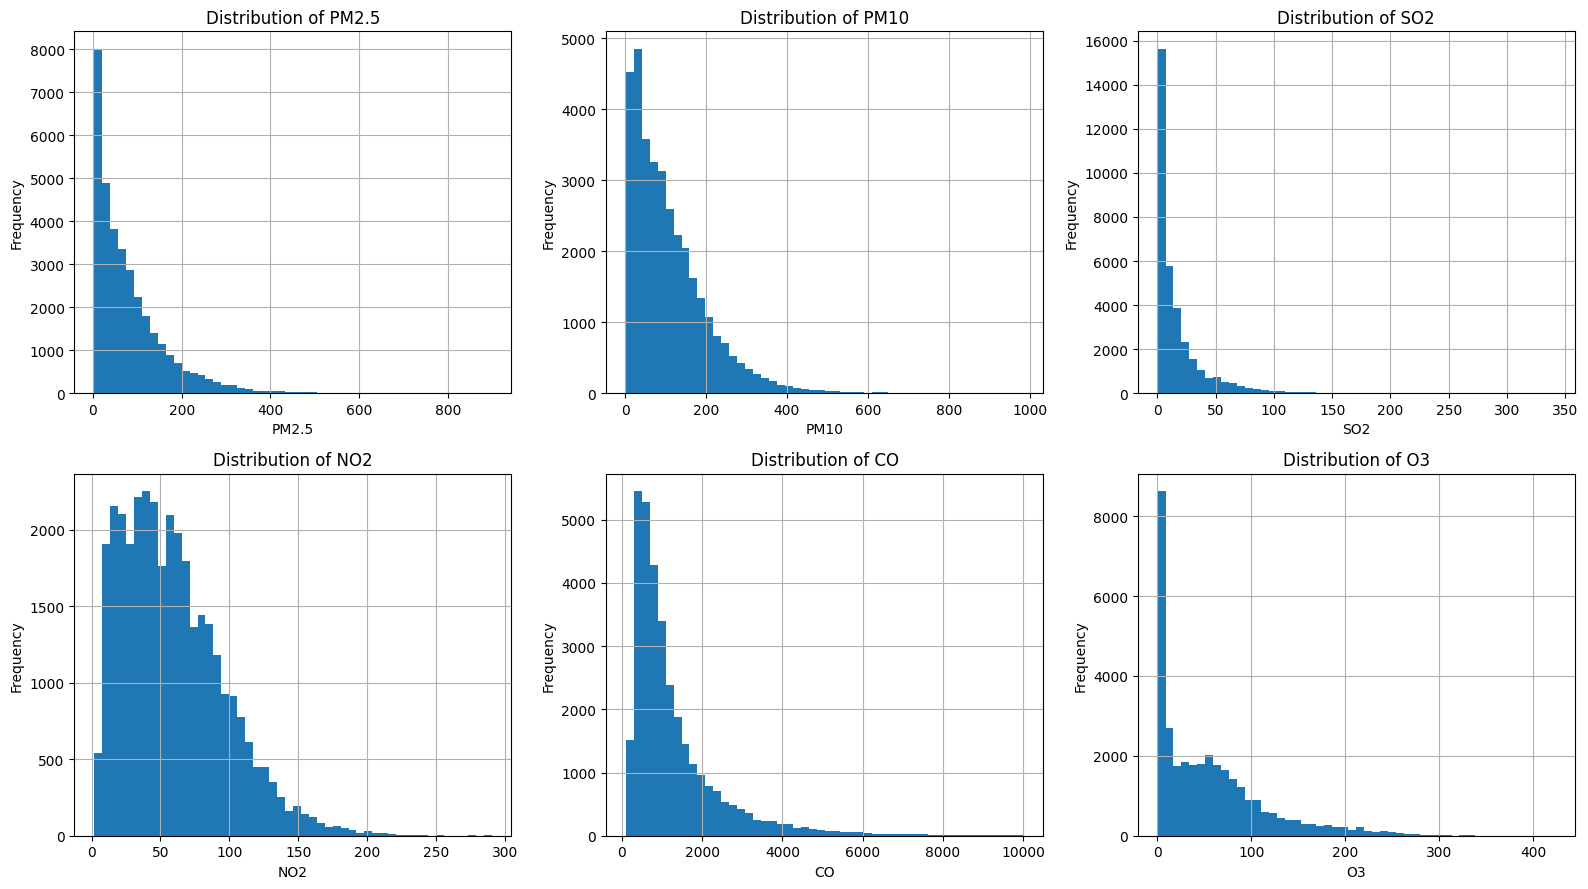

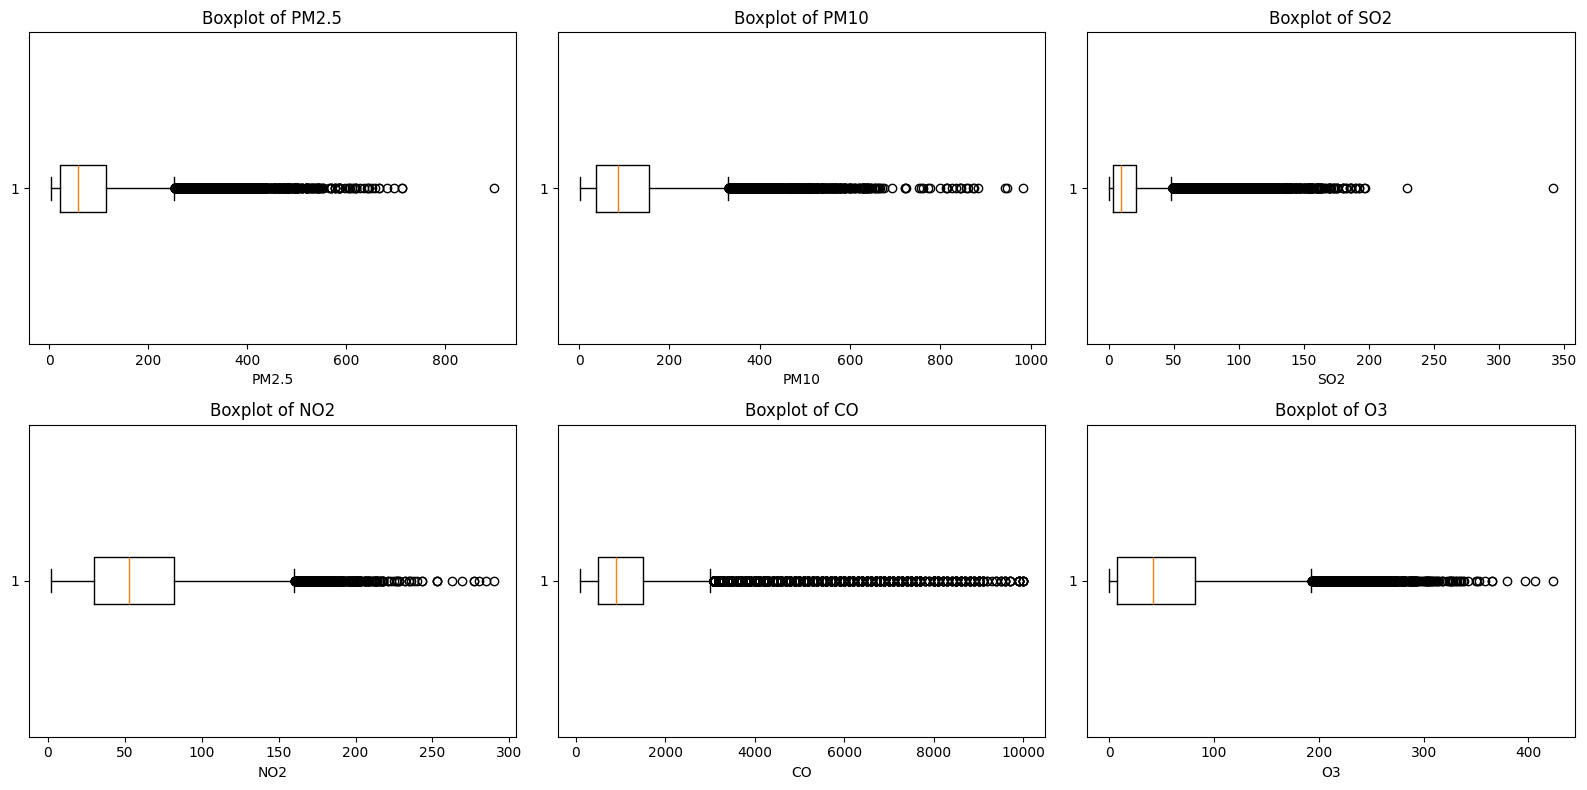

In [7]:

pollutants = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

# Plot histograms
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(pollutants, axes.flatten()):
    df[col].dropna().hist(bins=50, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Plot boxplots to inspect extreme values
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col, ax in zip(pollutants, axes.flatten()):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()


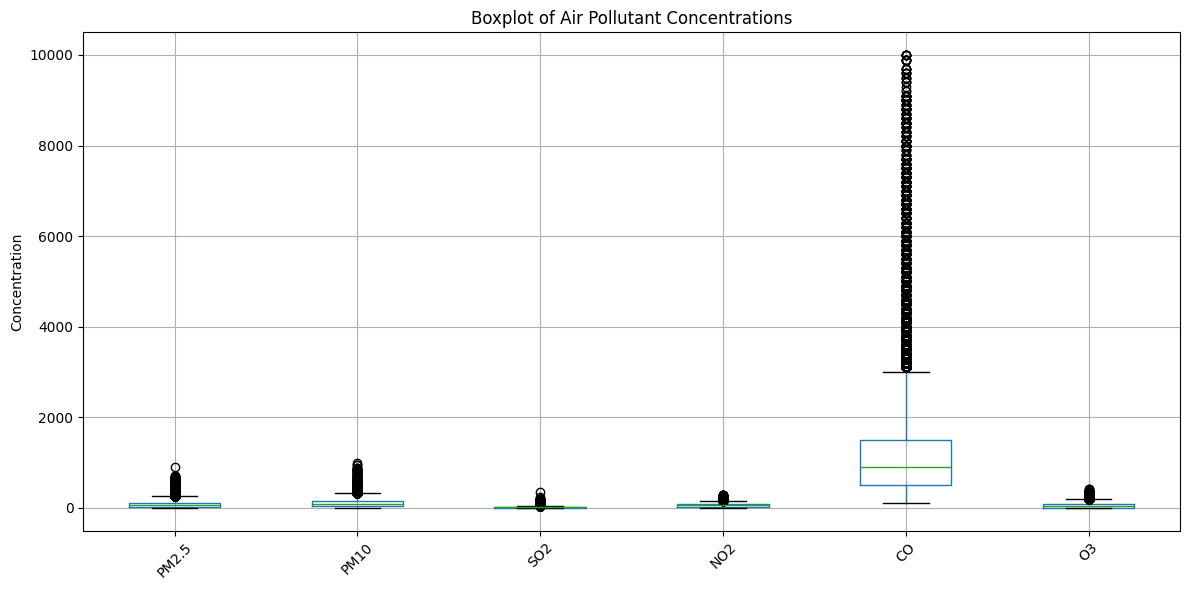

In [8]:
import matplotlib.pyplot as plt

pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

plt.figure(figsize=(12, 6))

df[pollutants].boxplot()

plt.title('Boxplot of Air Pollutant Concentrations')
plt.ylabel('Concentration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [9]:
pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

for col in pollutants:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[col].notna() & (
        (df[col] < lower) | (df[col] > upper)
    )

    print(f"{col}: {outliers.sum()} potential outliers "
          f"({outliers.mean() * 100:.2f}%)")

PM2.5: 1624 potential outliers (4.63%)
PM10: 1080 potential outliers (3.08%)
SO2: 3054 potential outliers (8.71%)
NO2: 472 potential outliers (1.35%)
CO: 2607 potential outliers (7.43%)
O3: 1310 potential outliers (3.74%)


In [10]:
pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

print("Missing values:")
print(df[pollutants].isnull().sum())

print("\nAvailable records for anomaly detection:")
print(df[pollutants].dropna().shape)

Missing values:
PM2.5     925
PM10      718
SO2       935
NO2      1023
CO       1776
O3       1719
dtype: int64

Available records for anomaly detection:
(31896, 6)


In [11]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import pandas as pd

pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']

# Keep records with all six pollutant measurements
X = df[pollutants].dropna().copy()

# Scale the features so their numerical ranges are comparable
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original dataset shape:", df.shape)
print("Data prepared for anomaly detection:", X.shape)
print("Scaled feature shape:", X_scaled.shape)

Original dataset shape: (35064, 19)
Data prepared for anomaly detection: (31896, 6)
Scaled feature shape: (31896, 6)


In [12]:
# Create the Isolation Forest model
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

# Train the model and predict anomalies
predictions = model.fit_predict(X_scaled)

# Store the results
results = X.copy()
results['anomaly'] = predictions

# Convert predictions into readable labels
results['anomaly'] = results['anomaly'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

# Display the results
print(results['anomaly'].value_counts())

print("\nSample detected anomalies:")
print(results[results['anomaly'] == 'Anomaly'].head(10))

anomaly
Normal     30301
Anomaly     1595
Name: count, dtype: int64

Sample detected anomalies:
     PM2.5   PM10    SO2    NO2      CO    O3  anomaly
105  114.0  159.0  114.0   92.0  2899.0  84.0  Anomaly
106  131.0  177.0  107.0  104.0  2700.0  84.0  Anomaly
107  138.0  184.0  109.0  115.0  2299.0  84.0  Anomaly
109  163.0  193.0   94.0  147.0  2200.0  84.0  Anomaly
110  168.0  182.0   85.0  158.0  2100.0  84.0  Anomaly
111  165.0  171.0   85.0  172.0  2200.0  78.0  Anomaly
112  166.0  186.0   97.0  194.0  2700.0  78.0  Anomaly
113  190.0  218.0  101.0  204.0  2799.0  75.0  Anomaly
114  203.0  248.0  107.0  197.0  2500.0  53.0  Anomaly
115  210.0  255.0  103.0  188.0  2200.0  40.0  Anomaly


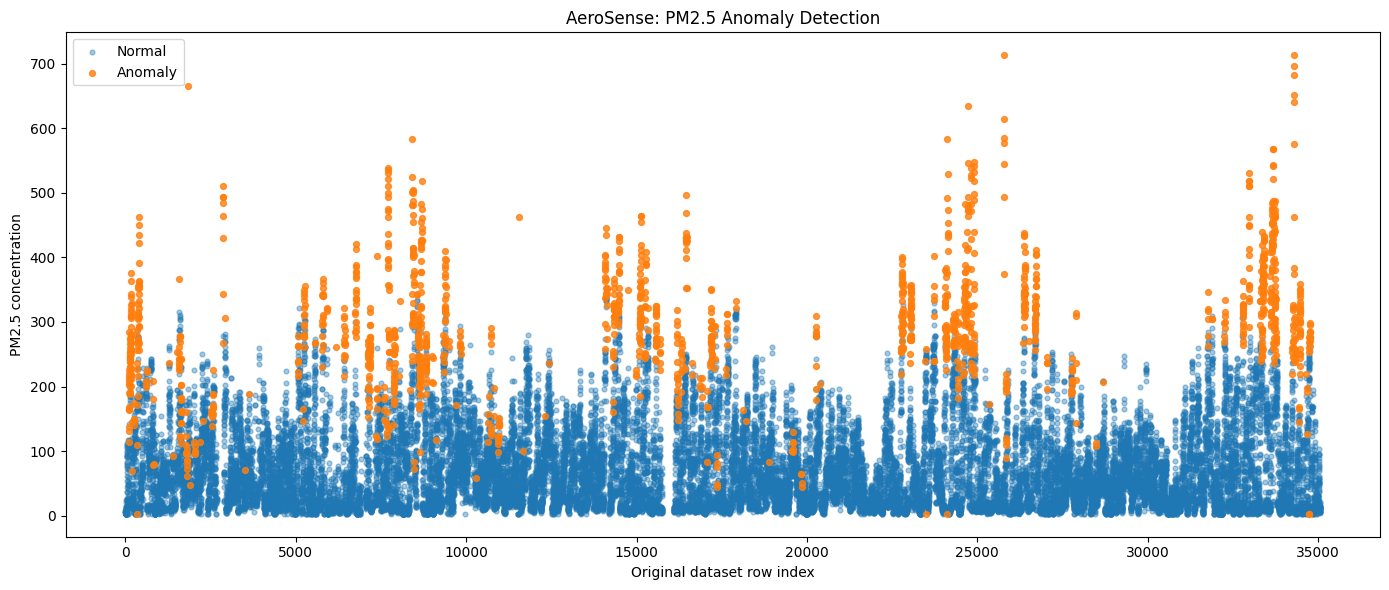

In [13]:
import matplotlib.pyplot as plt

# Use the original row indices to align the anomaly labels
plt.figure(figsize=(14, 6))

normal = results['anomaly'] == 'Normal'
anomaly = results['anomaly'] == 'Anomaly'

plt.scatter(
    results.index[normal],
    results.loc[normal, 'PM2.5'],
    label='Normal',
    alpha=0.4,
    s=12
)

plt.scatter(
    results.index[anomaly],
    results.loc[anomaly, 'PM2.5'],
    label='Anomaly',
    alpha=0.8,
    s=18
)

plt.title('AeroSense: PM2.5 Anomaly Detection')
plt.xlabel('Original dataset row index')
plt.ylabel('PM2.5 concentration')
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# Get the original row indices used in anomaly detection
results['year'] = df.loc[results.index, 'year']
results['month'] = df.loc[results.index, 'month']
results['day'] = df.loc[results.index, 'day']
results['hour'] = df.loc[results.index, 'hour']

# Create a proper timestamp
results['timestamp'] = pd.to_datetime(
    results[['year', 'month', 'day', 'hour']]
)

# Display the detected anomalies with their timestamps
anomalies = results[results['anomaly'] == 'Anomaly']

print("Total anomalies:", len(anomalies))
print("\nFirst 10 detected anomalies:")
print(
    anomalies[
        ['timestamp', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
    ].head(10).to_string(index=False)
)

Total anomalies: 1595

First 10 detected anomalies:
          timestamp  PM2.5  PM10   SO2   NO2     CO   O3
2013-03-05 09:00:00  114.0 159.0 114.0  92.0 2899.0 84.0
2013-03-05 10:00:00  131.0 177.0 107.0 104.0 2700.0 84.0
2013-03-05 11:00:00  138.0 184.0 109.0 115.0 2299.0 84.0
2013-03-05 13:00:00  163.0 193.0  94.0 147.0 2200.0 84.0
2013-03-05 14:00:00  168.0 182.0  85.0 158.0 2100.0 84.0
2013-03-05 15:00:00  165.0 171.0  85.0 172.0 2200.0 78.0
2013-03-05 16:00:00  166.0 186.0  97.0 194.0 2700.0 78.0
2013-03-05 17:00:00  190.0 218.0 101.0 204.0 2799.0 75.0
2013-03-05 18:00:00  203.0 248.0 107.0 197.0 2500.0 53.0
2013-03-05 19:00:00  210.0 255.0 103.0 188.0 2200.0 40.0


In [15]:
# Sort observations chronologically
results = results.sort_values('timestamp').copy()

# Mark whether each observation is an anomaly
results['is_anomaly'] = results['anomaly'] == 'Anomaly'

# Create a new event whenever anomalies stop or a gap occurs
previous_anomaly = results['is_anomaly'].shift(fill_value=False)
time_gap = results['timestamp'].diff().ne(pd.Timedelta(hours=1))

results['new_event'] = (
    results['is_anomaly'] &
    (~previous_anomaly | time_gap)
)

results['event_id'] = results['new_event'].cumsum()

# Keep only anomalous observations
anomalies = results[results['is_anomaly']].copy()

# Summarize consecutive anomalous hours
events = anomalies.groupby('event_id').agg(
    start_time=('timestamp', 'min'),
    end_time=('timestamp', 'max'),
    anomalous_hours=('timestamp', 'count'),
    avg_PM25=('PM2.5', 'mean'),
    max_PM25=('PM2.5', 'max'),
    avg_PM10=('PM10', 'mean')
).reset_index(drop=True)

print("Number of detected anomaly periods:", len(events))
print("\nLongest periods:")
print(
    events.sort_values('anomalous_hours', ascending=False)
          .head(10)
          .to_string(index=False)
)

Number of detected anomaly periods: 332

Longest periods:
         start_time            end_time  anomalous_hours   avg_PM25  max_PM25   avg_PM10
2016-12-20 13:00:00 2016-12-22 02:00:00               38 372.789474     433.0 372.789474
2016-12-31 15:00:00 2017-01-02 03:00:00               37 446.918919     568.0 469.378378
2013-03-06 12:00:00 2013-03-07 16:00:00               29 251.965517     320.0 306.517241
2013-12-24 14:00:00 2013-12-25 14:00:00               25 262.160000     321.0 308.560000
2014-02-23 11:00:00 2014-02-24 10:00:00               24 210.500000     247.0 280.375000
2017-02-03 17:00:00 2017-02-04 14:00:00               22 298.954545     359.0 301.681818
2014-10-18 16:00:00 2014-10-19 12:00:00               21 304.380952     367.0 427.428571
2014-11-20 14:00:00 2014-11-21 10:00:00               21 339.666667     464.0 450.428571
2014-03-03 07:00:00 2014-03-04 02:00:00               20 241.700000     281.0 281.300000
2014-02-15 06:00:00 2014-02-16 01:00:00             

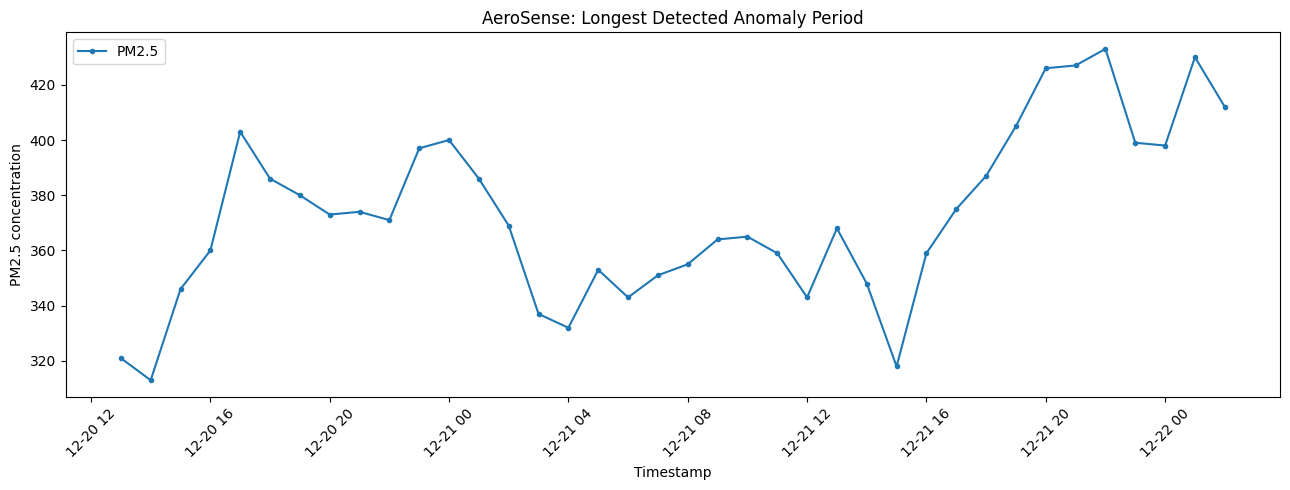

In [16]:
import matplotlib.pyplot as plt

# Select the longest detected anomaly period
longest_event = events.loc[
    events['anomalous_hours'].idxmax()
]

start = longest_event['start_time']
end = longest_event['end_time']

# Get the readings during that period
event_data = results[
    (results['timestamp'] >= start) &
    (results['timestamp'] <= end)
].copy()

plt.figure(figsize=(13, 5))

plt.plot(
    event_data['timestamp'],
    event_data['PM2.5'],
    marker='o',
    markersize=3,
    label='PM2.5'
)

plt.title('AeroSense: Longest Detected Anomaly Period')
plt.xlabel('Timestamp')
plt.ylabel('PM2.5 concentration')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# Count the model's classifications
print("Anomaly detection summary")
print("-------------------------")

total = len(results)
normal_count = (results['anomaly'] == 'Normal').sum()
anomaly_count = (results['anomaly'] == 'Anomaly').sum()

print("Total observations:", total)
print("Normal observations:", normal_count)
print("Detected anomalies:", anomaly_count)
print("Anomaly percentage:", round(anomaly_count / total * 100, 2), "%")

print("\nAverage pollutant concentrations")
print(
    results.groupby('anomaly')[
        ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
    ].mean().round(2)
)

Anomaly detection summary
-------------------------
Total observations: 31896
Normal observations: 30301
Detected anomalies: 1595
Anomaly percentage: 5.0 %

Average pollutant concentrations
          PM2.5    PM10    SO2     NO2       CO     O3
anomaly                                               
Anomaly  297.08  337.18  60.99  126.47  4380.97  39.01
Normal    70.56   97.12  14.85   55.47  1092.94  57.09


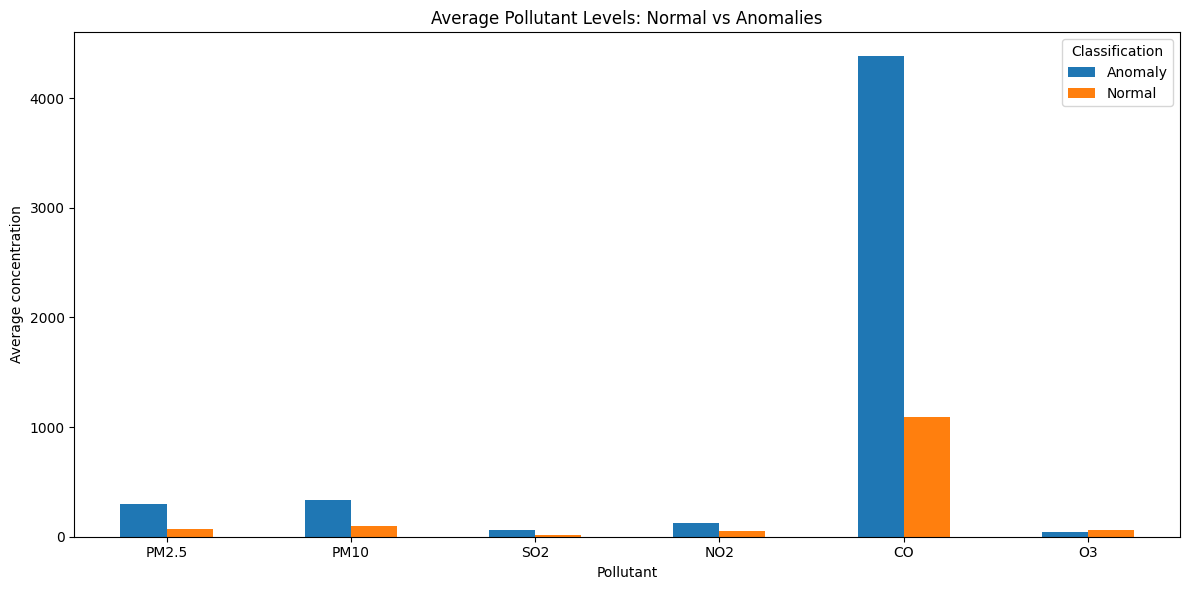

In [18]:
import matplotlib.pyplot as plt

comparison = results.groupby('anomaly')[
    ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
].mean().T

comparison.plot(kind='bar', figsize=(12, 6))

plt.title('Average Pollutant Levels: Normal vs Anomalies')
plt.xlabel('Pollutant')
plt.ylabel('Average concentration')
plt.xticks(rotation=0)
plt.legend(title='Classification')
plt.tight_layout()
plt.show()

In [19]:
# Select the columns to display in the anomaly report
report_columns = [
    'timestamp',
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'anomaly'
]

anomaly_report = (
    results.loc[results['anomaly'] == 'Anomaly', report_columns]
    .sort_values('timestamp')
    .reset_index(drop=True)
)

print("Total detected anomalies:", len(anomaly_report))
display(anomaly_report.head(20))

Total detected anomalies: 1595


,timestamp,PM2.5,PM10,SO2,NO2,CO,O3,anomaly
0,2013-03-05 09:00:00,114.0,159.0,114.0,92.0,2899.0,84.0,Anomaly
1,2013-03-05 10:00:00,131.0,177.0,107.0,104.0,2700.0,84.0,Anomaly
2,2013-03-05 11:00:00,138.0,184.0,109.0,115.0,2299.0,84.0,Anomaly
3,2013-03-05 13:00:00,163.0,193.0,94.0,147.0,2200.0,84.0,Anomaly
4,2013-03-05 14:00:00,168.0,182.0,85.0,158.0,2100.0,84.0,Anomaly
5,2013-03-05 15:00:00,165.0,171.0,85.0,172.0,2200.0,78.0,Anomaly
6,2013-03-05 16:00:00,166.0,186.0,97.0,194.0,2700.0,78.0,Anomaly
7,2013-03-05 17:00:00,190.0,218.0,101.0,204.0,2799.0,75.0,Anomaly
8,2013-03-05 18:00:00,203.0,248.0,107.0,197.0,2500.0,53.0,Anomaly
9,2013-03-05 19:00:00,210.0,255.0,103.0,188.0,2200.0,40.0,Anomaly


In [20]:
# Export detected anomalies
anomaly_report.to_csv(
    'aerosense_anomaly_report.csv',
    index=False
)

# Export the detected anomaly periods
events.to_csv(
    'aerosense_detected_events.csv',
    index=False
)

print("Files exported successfully:")
print("1. aerosense_anomaly_report.csv")
print("2. aerosense_detected_events.csv")

Files exported successfully:
1. aerosense_anomaly_report.csv
2. aerosense_detected_events.csv


In [21]:
from google.colab import files

files.download('aerosense_anomaly_report.csv')
files.download('aerosense_detected_events.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>